# HypotheSAEs on Hippocorpus: what distinguishes recalled from imagined stories?

Runs the HypotheSAEs pipeline (embed → SAE → select neurons → interpret → evaluate) on **Hippocorpus** (Sap et al., ACL 2020): ~5.5K first-person stories that people either **recalled** from their own lives or **imagined** from a short summary.

Setup used here:
- **Embeddings + SAE**: run in this Colab session (use a GPU runtime: *Runtime → Change runtime type → T4 GPU*).
- **LLM (interpretation + annotation)**: Qwen3-8B served with vLLM on Modal as an OpenAI-compatible endpoint (`modal/vllm_server.py`).
- Annotation uses `prompt_suffix=" /no_think"` (added in this fork) to turn off Qwen3 thinking for yes/no calls; interpretation keeps thinking on.

Before running: add a Colab secret (key icon in the left sidebar) named `MODAL_VLLM_KEY` with the server's API key, and enable notebook access.

In [1]:
!pip install -q git+https://github.com/psnandini/HypotheSAEs.git
!nvidia-smi --query-gpu=name,memory.total --format=csv


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
import os
from google.colab import userdata, files

os.environ["OPENAI_BASE_URL"] = "https://psnandini--hypothesaes-vllm-serve.us-east.modal.run/v1"
os.environ["OPENAI_KEY_SAE"] = userdata.get("MODAL_VLLM_KEY")
os.environ["EMB_CACHE_DIR"] = "/content/emb_cache"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hypothesaes.quickstart import train_sae, interpret_sae, generate_hypotheses, evaluate_hypotheses
from hypothesaes.embedding import get_local_embeddings
from hypothesaes.llm_api import get_completion

MODEL = "Qwen/Qwen3-8B"
INTERPRETER_MODEL = ANNOTATOR_MODEL = MODEL
OUT = "/content/results"   # every result table is saved here and downloaded right away
os.makedirs(OUT, exist_ok=True)

**Wake up the LLM server.** The Modal server scales to zero when idle, so the first call can take 2–3 minutes while a GPU starts. Later calls are fast.

In [3]:
import time
t = time.time()
print(get_completion(prompt="Reply with the single word: ready /no_think", model=MODEL))
print(f"{time.time() - t:.0f} s")



ready
256 s


## 0. Load Hippocorpus

Downloaded from the official Microsoft source (Open Use of Data Agreement). We keep **recalled** and **imagined** stories; label = 1 for recalled, 0 for imagined.

Each imagined story was written from the summary of a recalled story (`recImgPairId`), so the two share a topic. We keep each pair in the same split so that topic cannot leak between train and held-out data.

In [4]:
!wget -q -nc https://download.microsoft.com/download/3/c/3/3c388755-ac68-4858-8343-9acfb33c631d/hippocorpus-u20220112.zip
!unzip -q -o hippocorpus-u20220112.zip -d hippocorpus

df = pd.read_csv("hippocorpus/hcV3-stories.csv", encoding="latin-1")
df = df[df.memType.isin(["recalled", "imagined"])].dropna(subset=["story"]).reset_index(drop=True)
df["label"] = (df.memType == "recalled").astype(int)
# pair id: a recalled story's own id, or the recalled story an imagined one was based on
df["pair_id"] = np.where(df.memType == "recalled", df.AssignmentId, df.recImgPairId.fillna(df.AssignmentId))
df["n_words"] = df.story.str.split().str.len()
print(df.memType.value_counts())

memType
recalled    2779
imagined    2756
Name: count, dtype: int64


In [5]:
rng = np.random.default_rng(0)
pairs = rng.permutation(np.asarray(df.pair_id.unique(), dtype=object))
n = len(pairs)
split_of = {p: "train" for p in pairs[: int(0.7 * n)]}
split_of.update({p: "val" for p in pairs[int(0.7 * n): int(0.8 * n)]})
split_of.update({p: "holdout" for p in pairs[int(0.8 * n):]})
df["split"] = df.pair_id.map(split_of)
print(df.groupby(["split", "memType"]).size().unstack())

train_df, val_df, holdout_df = (df[df.split == s].reset_index(drop=True) for s in ["train", "val", "holdout"])
texts, labels = train_df.story.tolist(), train_df.label.values
val_texts = val_df.story.tolist()

memType  imagined  recalled
split                      
holdout       545       556
train        1932      1945
val           279       278


Quick check: story length by class. If length alone separated the classes strongly, many "hypotheses" could just be length proxies.

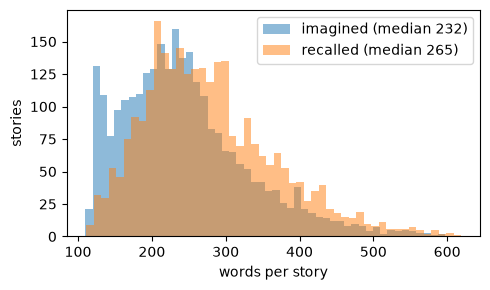

In [6]:
fig, ax = plt.subplots(figsize=(5, 3))
for name, g in df.groupby("memType"):
    ax.hist(g.n_words, bins=50, alpha=0.5, label=f"{name} (median {g.n_words.median():.0f})")
ax.set_xlabel("words per story"); ax.set_ylabel("stories"); ax.legend(); plt.tight_layout(); plt.show()

## 1. Text embeddings

`nomic-ai/modernbert-embed-base`, the local embedder used in the HypotheSAEs local quickstart. Embeddings are cached in `EMB_CACHE_DIR`.

In [7]:
EMBEDDER = "nomic-ai/modernbert-embed-base"
CACHE_NAME = "hippocorpus_modernbert"

text2embedding = get_local_embeddings(texts + val_texts, model=EMBEDDER, batch_size=64, cache_name=CACHE_NAME)
train_embeddings = np.stack([text2embedding[t] for t in texts])
val_embeddings = np.stack([text2embedding[t] for t in val_texts])
print(train_embeddings.shape, val_embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/210 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/445k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  596MB            

... (6 outputs left out)

Loaded model nomic-ai/modernbert-embed-base to cuda


Processing chunks:   0%|          | 0/1 [00:00<?, ?it/s]

Chunk 0:   0%|          | 0/70 [00:00<?, ?it/s]

Saved 4434 embeddings to /content/emb_cache/hippocorpus_modernbert/chunk_000.npy
(3877, 768) (557, 768)


## 2. Train the SAE

Same settings as the quickstart: Matryoshka SAE with M=256 neurons, K=8 active per text, prefixes [32, 256]. Hippocorpus is small (~3.9K training stories), so check the reconstruction and dead-neuron numbers printed during training; a smaller M is worth trying if many neurons are dead.

In [8]:
import torch
torch.manual_seed(0); np.random.seed(0)   # fixed seed so the SAE is reproducible
sae = train_sae(
    embeddings=train_embeddings, M=256, K=8, matryoshka_prefix_lengths=[32, 256],
    checkpoint_dir="/content/checkpoints/hippocorpus", val_embeddings=val_embeddings,
)

  0%|          | 0/100 [00:00<?, ?it/s]

Early stopping triggered after 75 epochs
Saved model to /content/checkpoints/hippocorpus/SAE_matryoshka_M=256_K=8_prefixes=32-256.pt


## 3. Sanity check: interpret a few random neurons

In [9]:
TASK_SPECIFIC_INSTRUCTIONS = """All of the texts are short first-person stories written by crowdworkers about an event in their life.
Features should describe a specific property of the story's content or writing style. For example:
- "mentions a pet or animal"
- "describes a conversation with a family member"
"""

INTERPRET_LLM_KWARGS = {}                              # thinking on for interpretation
ANNOTATION_LLM_KWARGS = {"prompt_suffix": " /no_think"}  # thinking off for yes/no annotation

random_results = interpret_sae(
    texts=texts, embeddings=train_embeddings, sae=sae,
    interpreter_model=INTERPRETER_MODEL, n_random_neurons=5, print_examples_n=3,
    task_specific_instructions=TASK_SPECIFIC_INSTRUCTIONS, interpret_llm_kwargs=INTERPRET_LLM_KWARGS,
)

Computing activations (batchsize=16384):   0%|          | 0/1 [00:00<?, ?it/s]

Activations shape: (3877, 256)


Generating interpretations:   0%|          | 0/5 [00:00<?, ?it/s]


Neuron 158 (0.8% active): mentions a personal struggle involving a decision to change one's life circumstances, such as quitting a job or changing a career

Top activating examples:
1. For the last couple of years I have been really trying to teach myself the good word of the Bible. Religion has had such an effect on me, powerful and loving, that I want to spread the message to others. A couple of months ago I decided that I might even be comfortable enough with the teachings that maybe I could teach a class. I decide the best step for me would be to teach to adults, not to children. So, I signed up to teach a class this fall. Last week, I was preparing for the first lesson. I wanted to be extra prepared for next week, which is the first class, so I started early. Well wouldn't you know, I encountered a passage that really touched me deep down. I had read it before, but it didn't affect me the way it did a week ago. It was really touching, and really moved me. It said that I must ador

## 4. Generate hypotheses

Select the 20 neurons most correlated with the label, interpret each, and score each interpretation's fidelity (F1 between the neuron firing and the LLM's annotation of the concept).

In [10]:
results = generate_hypotheses(
    texts=texts, labels=labels, embeddings=train_embeddings, sae=sae,
    interpreter_model=INTERPRETER_MODEL, annotator_model=ANNOTATOR_MODEL,
    selection_method="correlation", n_selected_neurons=20, n_candidate_interpretations=1,
    task_specific_instructions=TASK_SPECIFIC_INSTRUCTIONS,
    interpret_llm_kwargs=INTERPRET_LLM_KWARGS, annotation_llm_kwargs=ANNOTATION_LLM_KWARGS,
    n_workers_interpretation=8, n_workers_annotation=32,
)
pd.set_option("display.max_colwidth", None)
display(results.sort_values("target_correlation", ascending=False))
results.to_csv(f"{OUT}/hippocorpus_hypotheses.csv", index=False)
files.download(f"{OUT}/hippocorpus_hypotheses.csv")

Embeddings shape: (3877, 768)


Computing activations (batchsize=16384):   0%|          | 0/1 [00:00<?, ?it/s]

Activations shape: (3877, 256)

Step 1: Selecting top 20 predictive neurons



Step 2: Interpreting selected neurons


/usr/local/lib/python3.12/site-packages/hypothesaes/select_neurons.py:130: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  pearsonr(activations[:, i], target)[0]


Generating interpretations:   0%|          | 0/20 [00:00<?, ?it/s]


Step 3: Scoring Interpretations
Found 0 cached items; annotating 2000 uncached items


Scoring neuron interpretation fidelity (20 neurons; 1 candidate interps per neuron; 100 examples to score each…

,neuron_idx,target_correlation,interpretation,f1_fidelity_score
0,244,0.094298,mentions a mental health challenge or spiritual practice,0.700855
6,111,0.055704,mentions a personal experience with a family member's death or a significant life event involving emotional impact,0.603774
8,26,0.049491,mentions a neighbor or new community member,0.534884
11,20,0.046111,mentions a wedding event,0.900901
13,15,0.044378,"mentions a child's life milestone such as starting school, learning to crawl, or graduating",0.862069
16,194,0.041901,mentions traveling to a new state or relocating to a different location,0.800000
17,164,0.041093,mentions legal incarceration or mental health treatment,0.848485
19,85,0.039976,mentions an unexpected personal revelation or crisis,0.701493
18,70,-0.040594,mentions the narrator's own personal loss,0.692308
15,72,-0.043725,mentions a specific event involving personal challenges or social interactions leading to some form of resolution or reflection,0.671141


(saved /content/results/hippocorpus_hypotheses.csv)


## 5. Evaluate on held-out stories

Annotate each hypothesis on held-out stories (pairs never seen during SAE training or neuron selection) and test whether it predicts recalled vs imagined.

In [11]:
metrics, evaluation_df = evaluate_hypotheses(
    hypotheses_df=results, texts=holdout_df.story.tolist(), labels=holdout_df.label.values,
    annotator_model=ANNOTATOR_MODEL, annotation_llm_kwargs=ANNOTATION_LLM_KWARGS, n_workers_annotation=32,
)
display(evaluation_df)
evaluation_df.to_csv(f"{OUT}/hippocorpus_holdout_eval.csv", index=False)
files.download(f"{OUT}/hippocorpus_holdout_eval.csv")
print(f"AUROC: {metrics['auroc']:.3f}")
print(f"Significant hypotheses: {metrics['Significant'][0]}/{metrics['Significant'][1]} (p < {metrics['Significant'][2]})")

Step 1: Annotating texts with 20 hypotheses
Found 0 cached items; annotating 22020 uncached items


Annotating:   0%|          | 0/22020 [00:00<?, ?it/s]

Step 2: Computing predictiveness of hypothesis annotations
         Current function value: 0.680710
         Iterations: 35


/usr/local/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,hypothesis,separation_score,separation_pval,regression_coef,regression_pval,feature_prevalence
15,mentions a specific event involving personal challenges or social interactions leading to some form of resolution or reflection,0.306387,0.171881,19.487250,0.998296,0.995459
10,describes a personal experience that led to a significant life change,0.134896,0.094075,0.624649,0.109745,0.963669
16,mentions traveling to a new state or relocating to a different location,0.056284,0.067830,0.350582,0.010416,0.396004
7,mentions the use of psychedelic substances,0.041284,0.701730,0.169306,0.703336,0.019982
4,mentions the birth of a child,0.036381,0.306220,0.214246,0.234559,0.235241
19,mentions an unexpected personal revelation or crisis,0.023493,0.536239,0.233836,0.220653,0.803815
13,"mentions a child's life milestone such as starting school, learning to crawl, or graduating",0.012050,0.702093,0.093568,0.582078,0.356040
11,mentions a wedding event,0.006115,0.875793,0.057945,0.729987,0.181653
6,mentions a personal experience with a family member's death or a significant life event involving emotional impact,0.005587,0.853567,0.256521,0.176483,0.540418
17,mentions legal incarceration or mental health treatment,0.005585,0.898104,0.084437,0.664578,0.138965


(saved /content/results/hippocorpus_holdout_eval.csv)
AUROC: 0.583
Significant hypotheses: 0/20 (p < 0.005)
